# 3. NaCl 扩散：第一次耦合运行

**目标。** 第一次运行 `mode: coupled`，用最简单的化学：没有任何固相的溶液。两种 NaCl 溶液（1 M 和 0.5 M）在 20 mm 柱的中间相遇并相互扩散。

`case.yaml` 中的新内容：

- **`transport.zones`**：两个分区 `high` 和 `low`，各自在 `chemistry.initial` 中有自己的配方；
- **`chemistry.inlet: {left: high, right: low}`**：两端各自固定为本分区平衡后的孔隙水；
- **`solid_phases: []`**：只有溶液。GEMS 只计算溶液的物种分布，孔隙率保持不变。

| | |
|---|---|
| 模式 | `coupled` |
| 算例文件夹 | `FEniCSx_GEMS/example/demo_NaCl_diffusion`（本 notebook 在其中运行） |
| 区域 | 20 mm，200 个单元，100 s，`dt` = 1 s |
| 运行时间 | 约 5 s |

## 输入文件

In [1]:
print(open('case.yaml').read())

# NaCl diffusion between two NaCl solutions (fenics-reaktoro Demos/NaCl_diffusion),
# with the four modules two folders up (FEniCSx_GEMS_Beginner).
# Run from this folder:  python ../../coupling.py case.yaml   (or Run.cmd, or the notebook)
#
# Original: 20 mm of free solution, 1 M NaCl on the left half, 0.5 M on the right half,
# both ends held at their initial solution, Nernst-Planck transport, 100 s, dt = 1 s.
# Here x runs 0..0.02 m (original -0.01..0.01 m), interface at x = 0.01 m.

# 1. chemistry.py: GEMS project, chemical conditions, and recipes.
chemistry:
  project: chemistry_data/nacl-dat.lst
  temperature: 298.15                  # K
  pressure: 100000                     # Pa
  aqueous_phase: aq_gen
  solid_phases: []                     # solution only
  gibbs: {}

  # Sample per zone: element amounts in mol per 1 dm3 of BULK (= 1 dm3 of solution here).
  # = the GEMS DBR states nacl (1 M) and naclLOW (0.5 M), scaled to 1 dm3.
  initial:
    high:
      Cl: 0.98127723044314

与 [教程 2](02_single_equilibrium.ipynb) 相比有三处变化：

```yaml
chemistry:
  initial:                 # 每个分区一个配方，而不是一个配方
    high: {Cl: 0.981, H: 108.9, Na: 0.981, O: 54.47}
    low:  {Cl: 0.495, H: 109.8, Na: 0.495, O: 54.90}
  inlet: {left: high, right: low}
transport:
  zones:
    - {name: high, from: 0.0,  to: 0.01}
    - {name: low,  from: 0.01, to: 0.02}
coupling:
  mode: coupled
```

分区没有给出自己的 `phi` 或 `De`，所以都使用 `material` 中的值，这里是 φ = 1 的自由溶液。

### 为什么这里一个扩散系数就够了

Na⁺ 和 Cl⁻ 单独扩散的速度不同（$D_\text{Na} = 1.334\times10^{-9}$，$D_\text{Cl} = 2.032\times10^{-9}$ m²/s）。在溶液中，电中性使两种离子一起移动。对 1:1 盐，Nernst–Planck 方程化为以盐扩散系数表示的 Fick 定律：

$$
D_\text{salt} = \frac{2 D_\text{Na} D_\text{Cl}}{D_\text{Na} + D_\text{Cl}} = 1.611\times10^{-9}\ \text{m}^2/\text{s},
$$

这就是文件中的 `De`。代码对所有元素使用同一个系数，所以本例是精确的；对于离子不同的混合盐溶液则不精确。

## 运行

In [2]:
!python ../../coupling.py case.yaml 2>&1 | grep -v gems3k | tail -n 4

step=60, time=60 s, balance=3.114e-11 mol/m2, chemistry=1.033e-08 mol/m3, water mismatch=0.00%
step=80, time=80 s, balance=4.062e-11 mol/m2, chemistry=1.080e-08 mol/m3, water mismatch=0.00%
step=100, time=100 s, balance=4.792e-11 mol/m2, chemistry=1.063e-08 mol/m3, water mismatch=0.00%
Saved: FEniCSx_GEMS/example/demo_NaCl_diffusion/results


## 与解析解比较

两个分别为 $c_H$ 和 $c_L$ 的半无限区域给出 $c(x,t) = \tfrac{c_H+c_L}{2} - \tfrac{c_H-c_L}{2}\,\mathrm{erf}\!\big((x-x_0)/2\sqrt{Dt}\big)$。100 s 内锋面展宽不到 1 mm，所以 10 mm 外的固定端没有影响。

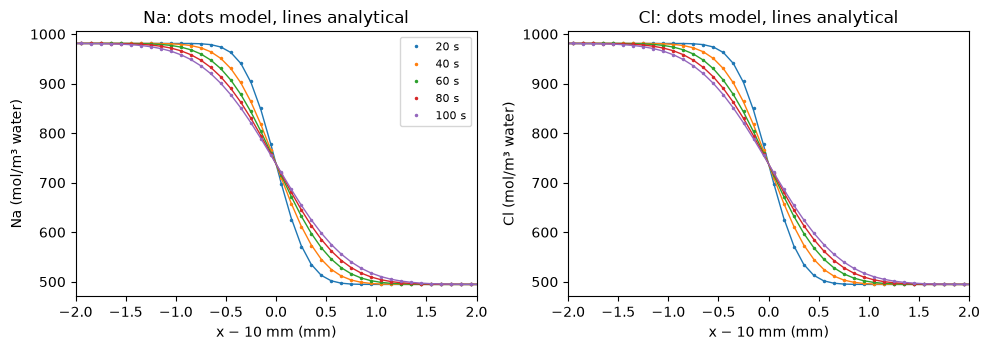

largest |model − analytical| / c_high: 0.43 %


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml
from scipy.special import erf

case = yaml.safe_load(open('case.yaml'))
p = pd.read_csv('results/profiles.csv')
D, x0 = case['transport']['material']['De'], 0.01
p0 = p[p.time_s == 0].sort_values('x_m')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
worst = 0.0
for ax, e in zip(axes, ('Na', 'Cl')):
    col = f'{e}_c_mol_m3_water'
    cH, cL = p0[col].iloc[0], p0[col].iloc[-1]
    for k, (t, g) in enumerate(p[p.time_s > 0].groupby('time_s')):
        x = g.sort_values('x_m').x_m.to_numpy()
        exact = (cH + cL) / 2 - (cH - cL) / 2 * erf((x - x0) / (2 * np.sqrt(D * t)))
        ax.plot((x - x0) * 1e3, g.sort_values('x_m')[col], '.', ms=3, color=f'C{k}', label=f'{t:g} s')
        ax.plot((x - x0) * 1e3, exact, '-', lw=1, color=f'C{k}')
        worst = max(worst, np.max(np.abs(g.sort_values('x_m')[col].to_numpy() - exact)) / cH)
    ax.set(xlim=(-2, 2), xlabel='x − 10 mm (mm)', ylabel=f'{e} (mol/m³ water)', title=f'{e}: dots model, lines analytical')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print(f'largest |model − analytical| / c_high: {100 * worst:.2f} %')

模型与 erf 解吻合得很好；微小差异来自 0.1 mm 的单元和一阶时间步。这里化学步几乎不起作用，只是重新计算溶液的物种分布。这正是本例的目的：在一个答案已知的问题上，把耦合循环完整跑通一遍。

## GEMS 带来了什么：pH 和水

每个元素都参与输运，包括水中的 H 和 O。GEMS 在每个单元重新计算溶液，因此 pH 和水量都由输运后的总量决定。

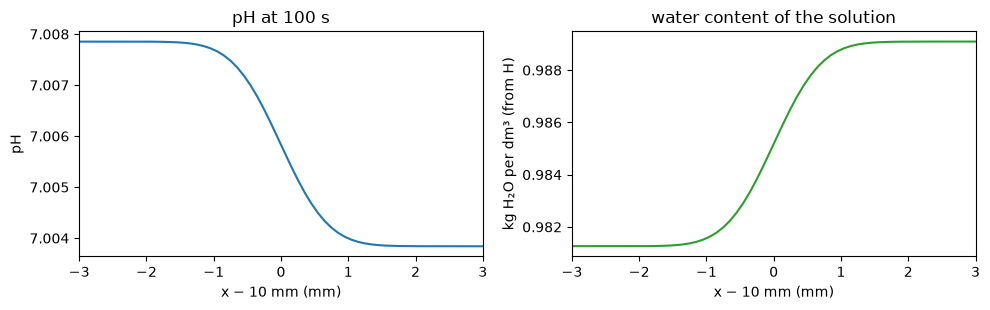

In [4]:
last = p[p.time_s == p.time_s.max()].sort_values('x_m')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))
a1.plot((last.x_m - x0) * 1e3, last.pH); a1.set(xlim=(-3, 3), xlabel='x − 10 mm (mm)', ylabel='pH', title='pH at 100 s')
a2.plot((last.x_m - x0) * 1e3, last.H_c_mol_m3_water / 2 / 1000 * 0.018015, color='C2')
a2.set(xlim=(-3, 3), xlabel='x − 10 mm (mm)', ylabel='kg H₂O per dm³ (from H)', title='water content of the solution')
plt.tight_layout(); plt.show()

1 M 溶液每升含水略少于 0.5 M 溶液，因为盐占据了体积。H 和 O 的输运把这一差异连同盐一起带走。

**下一篇：** [教程 4](04_cement_leaching.ipynb) 加入矿物，它们会随溶液变化而溶解。